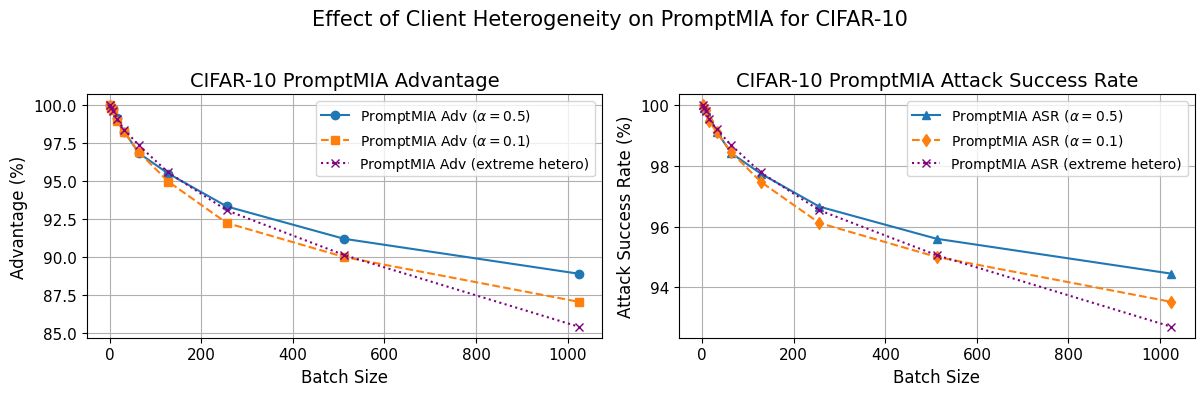

In [12]:
import matplotlib.pyplot as plt

# ----- Common batch sizes (8 points) -----
batch_sizes = [1, 4, 8, 16, 32, 64, 128, 256, 512, 1024]

# ===== CIFAR10, alpha = 0.5 (your original numbers, truncated to 8 entries) =====
# promptmia_adv_c10_a05 = [100.00, 99.84, 99.73, 99.14, 98.27, 96.85, 95.51, 93.34]
# promptmia_acc_c10_a05 = [100.00, 99.92, 99.86, 99.57, 99.13, 98.42, 97.75, 96.66]
promptmia_adv_c10_a05   = [100.00, 99.84, 99.73, 99.14, 98.27, 96.85, 95.51, 93.34,91.21,88.91]
promptmia_acc_c10_a05   = [100.00, 99.92, 99.86, 99.57, 99.13, 98.42, 97.75, 96.66,95.60,94.45]

# ===== CIFAR10, alpha = 0.1 (parsed from your log) =====
# Advantage (TNR) from the log
promptmia_adv_c10_a01 = [100.00, 99.86, 99.71, 98.96, 98.23, 96.91, 94.98, 92.25, 90.01, 87.06]

# Attack success / accuracy from the log (rounded to 2 decimals)
promptmia_acc_c10_a01 = [100.00, 99.92, 99.85, 99.47, 99.11, 98.45, 97.48, 96.12, 95.00, 93.52]

# ===== CIFAR10, manual extreme heterogeneity =====
promptmia_adv_c10_extreme = [100.00, 99.82, 99.61, 99.09, 98.41, 97.36, 95.58, 93.08, 90.14, 85.42]
promptmia_acc_c10_extreme = [99.99999999994999, 99.90999999995009, 99.80499999995018, 99.54499999995046,
                             99.2049999999508, 98.67999999995132, 97.78999999999522, 96.53999999995347, 95.06,92.7]

# ===== Plot: 2 subplots – Advantage and Attack Success Rate =====
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- (a) Advantage ---
ax = axes[0]
ax.plot(batch_sizes, promptmia_adv_c10_a05, marker="o", linestyle="-",
        label=r"PromptMIA Adv ($\alpha=0.5$)")
ax.plot(batch_sizes, promptmia_adv_c10_a01, marker="s", linestyle="--",
        label=r"PromptMIA Adv ($\alpha=0.1$)")
ax.plot(batch_sizes, promptmia_adv_c10_extreme, marker="x", linestyle=":", color='purple',
        label='PromptMIA Adv (extreme hetero)')

ax.set_title("CIFAR-10 PromptMIA Advantage", fontsize=14)
ax.set_xlabel("Batch Size", fontsize=12)
ax.set_ylabel("Advantage (%)", fontsize=12)
ax.grid(True)
ax.tick_params(axis='both', labelsize=11)
ax.legend(fontsize=10)

# --- (b) Attack Success Rate ---
ax = axes[1]
ax.plot(batch_sizes, promptmia_acc_c10_a05, marker="^", linestyle="-",
        label=r"PromptMIA ASR ($\alpha=0.5$)")
ax.plot(batch_sizes, promptmia_acc_c10_a01, marker="d", linestyle="--",
        label=r"PromptMIA ASR ($\alpha=0.1$)")
ax.plot(batch_sizes, promptmia_acc_c10_extreme, marker="x", linestyle=":", color='purple',
        label='PromptMIA ASR (extreme hetero)')

ax.set_title("CIFAR-10 PromptMIA Attack Success Rate", fontsize=14)
ax.set_xlabel("Batch Size", fontsize=12)
ax.set_ylabel("Attack Success Rate (%)", fontsize=12)
ax.grid(True)
ax.tick_params(axis='both', labelsize=11)
ax.legend(fontsize=10)

plt.suptitle("Effect of Client Heterogeneity on PromptMIA for CIFAR-10", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


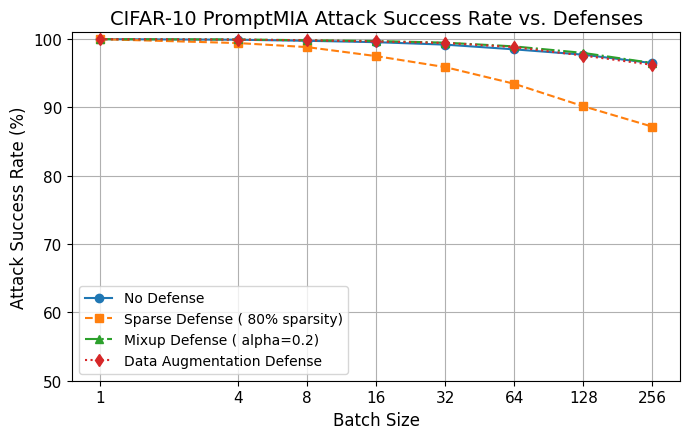

In [5]:
import matplotlib.pyplot as plt

batch_sizes = [1, 4, 8, 16, 32, 64, 128, 256]

# ASR (Attack Accuracy) from logs
asr_no_defense = [100.00, 99.92, 99.76, 99.56, 99.20, 98.51, 97.73, 96.49]
asr_sparse     = [100.00, 99.43, 98.84, 97.52, 95.91, 93.47, 90.18, 87.19]
asr_mixup      = [100.00, 99.96, 99.84, 99.73, 99.49, 98.94, 97.99, 96.51]
asr_dataaug    = [100.00, 99.93, 99.83, 99.66, 99.44, 98.84, 97.60, 96.24]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(batch_sizes, asr_no_defense, marker="o", linestyle="-",  label="No Defense")
ax.plot(batch_sizes, asr_sparse,     marker="s", linestyle="--", label="Sparse Defense ( 80% sparsity)")
ax.plot(batch_sizes, asr_mixup,      marker="^", linestyle="-.", label="Mixup Defense ( alpha=0.2)")
ax.plot(batch_sizes, asr_dataaug,    marker="d", linestyle=":",  label="Data Augmentation Defense")

ax.set_title("CIFAR-10 PromptMIA Attack Success Rate vs. Defenses", fontsize=14)
ax.set_xlabel("Batch Size", fontsize=12)
ax.set_ylabel("Attack Success Rate (%)", fontsize=12)
ax.set_ylim(50, 101)
ax.set_xscale("log", base=2)
ax.set_xticks(batch_sizes)
ax.set_xticklabels(batch_sizes)
ax.grid(True)
ax.tick_params(axis='both', labelsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

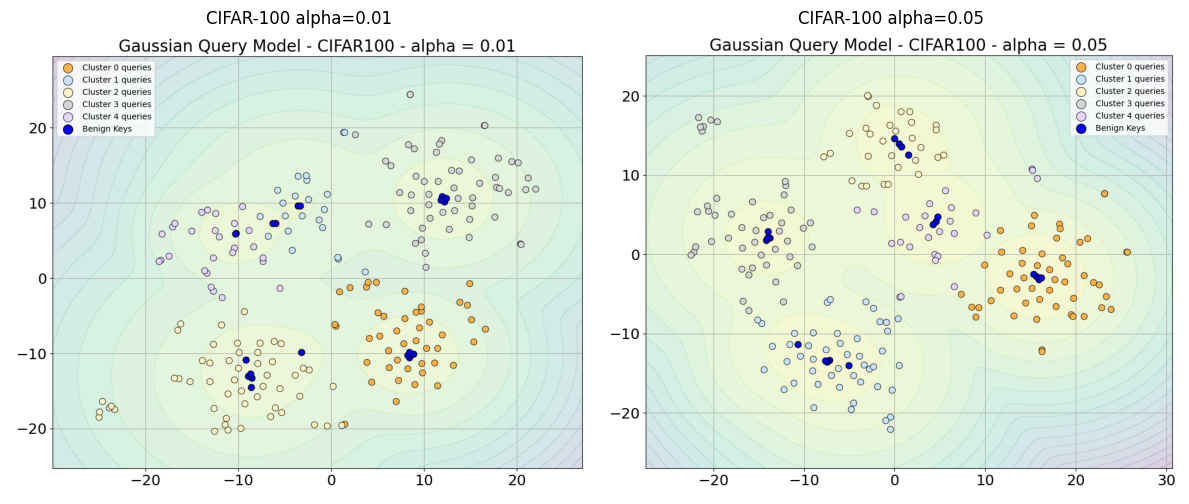

In [6]:
from PIL import Image
import matplotlib.pyplot as plt

img1 = Image.open('output/cifar100alpha001.png')
img2 = Image.open('output/cifar100alpha005.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img1)
axes[0].axis('off')
axes[0].set_title('CIFAR-100 alpha=0.01')

axes[1].imshow(img2)
axes[1].axis('off')
axes[1].set_title('CIFAR-100 alpha=0.05')

plt.tight_layout()
plt.show()

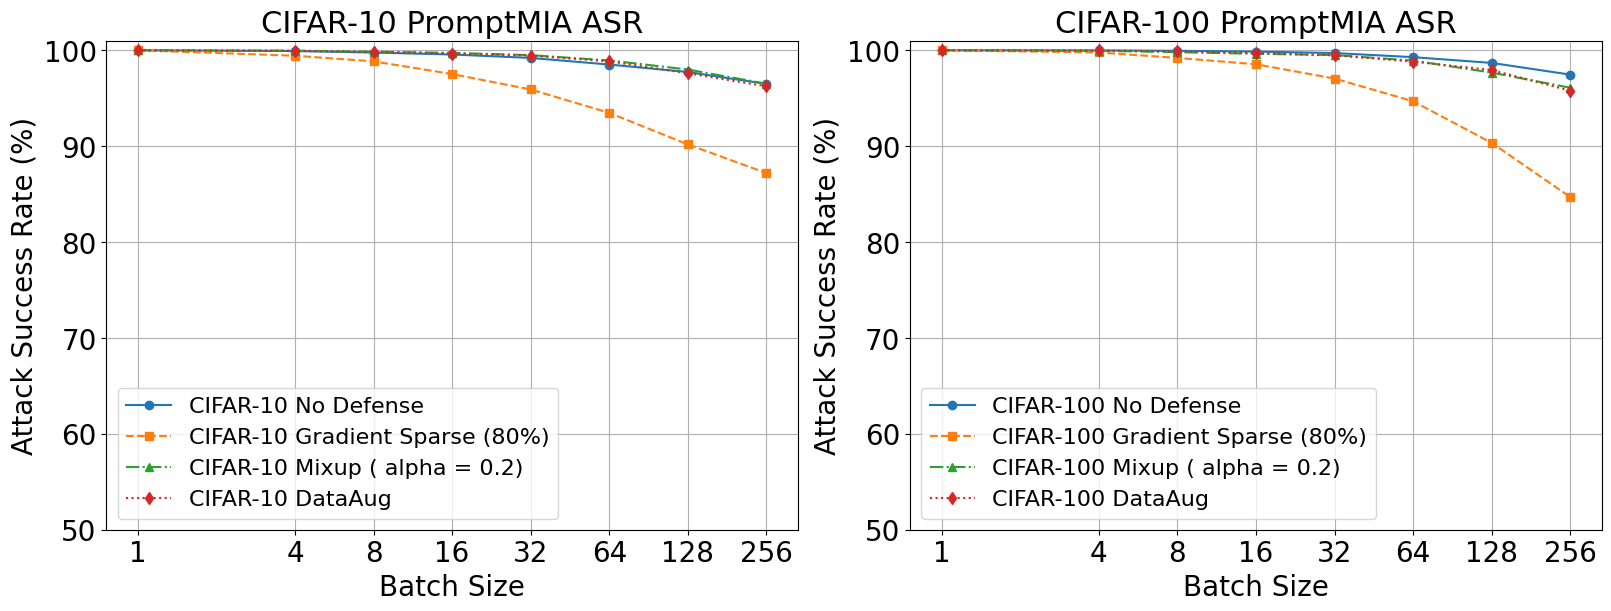

In [6]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Globally increase default font size for things like tick labels
plt.rcParams.update({'font.size': 14})

batch_sizes = [1, 4, 8, 16, 32, 64, 128, 256]
asr_no_defense = [100.00, 99.92, 99.76, 99.56, 99.20, 98.51, 97.73, 96.49]
asr_sparse     = [100.00, 99.43, 98.84, 97.52, 95.91, 93.47, 90.18, 87.19]
asr_mixup      = [100.00, 99.96, 99.84, 99.73, 99.49, 98.94, 97.99, 96.51]
asr_dataaug    = [100.00, 99.93, 99.83, 99.66, 99.44, 98.84, 97.60, 96.24]

# Assuming you still need these for something else later in your script
# cifar100_img1 = Image.open('output/cifar100alpha001.png')
# cifar100_img2 = Image.open('output/cifar100alpha005.png')

fig = plt.figure(constrained_layout=True, figsize=(16, 6)) # slightly increased figsize to accommodate larger fonts
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1, 1])

ax0 = fig.add_subplot(gs[0])
ax0.plot(batch_sizes, asr_no_defense, marker='o', linestyle='-', label='CIFAR-10 No Defense')
ax0.plot(batch_sizes, asr_sparse, marker='s', linestyle='--', label='CIFAR-10 Gradient Sparse (80%)')
ax0.plot(batch_sizes, asr_mixup, marker='^', linestyle='-.', label='CIFAR-10 Mixup ( alpha = 0.2)')
ax0.plot(batch_sizes, asr_dataaug, marker='d', linestyle=':', label='CIFAR-10 DataAug')
ax0.set_xscale('log', base=2)
ax0.set_xticks(batch_sizes)
ax0.set_xticklabels(batch_sizes)
ax0.set_ylim(50, 101)

# Increased font sizes here
ax0.set_title('CIFAR-10 PromptMIA ASR', fontsize=22)
ax0.set_xlabel('Batch Size', fontsize=20)
ax0.set_ylabel('Attack Success Rate (%)', fontsize=20)
ax0.tick_params(axis='both', which='major', labelsize=20)
ax0.grid(True)
ax0.legend(fontsize=16)
# CIFAR-100 ASR numbers from result logs
cifar100_no_defense = [100.00, 99.98, 99.94, 99.86, 99.71, 99.28, 98.68, 97.46]
cifar100_sparse     = [100.00, 99.77, 99.20, 98.54, 97.05, 94.68, 90.34, 84.69]
cifar100_mixup      = [100.00, 99.94, 99.80, 99.63, 99.50, 98.92, 97.67, 96.09]
cifar100_dataaug    = [100.00, 99.98, 99.89, 99.70, 99.47, 98.82, 97.94, 95.79]

ax1 = fig.add_subplot(gs[1])
ax1.plot(batch_sizes, cifar100_no_defense, marker='o', linestyle='-', label='CIFAR-100 No Defense')
ax1.plot(batch_sizes, cifar100_sparse, marker='s', linestyle='--', label='CIFAR-100 Gradient Sparse (80%)')
ax1.plot(batch_sizes, cifar100_mixup, marker='^', linestyle='-.', label='CIFAR-100 Mixup ( alpha = 0.2)')
ax1.plot(batch_sizes, cifar100_dataaug, marker='d', linestyle=':', label='CIFAR-100 DataAug')
ax1.set_xscale('log', base=2)
ax1.set_xticks(batch_sizes)
ax1.set_xticklabels(batch_sizes)
ax1.set_ylim(50, 101)

# Increased font sizes here
ax1.set_title('CIFAR-100 PromptMIA ASR', fontsize=22)
ax1.set_xlabel('Batch Size', fontsize=20)
ax1.set_ylabel('Attack Success Rate (%)', fontsize=20)
ax1.tick_params(axis='both', which='major', labelsize=20)
ax1.grid(True)
ax1.legend(fontsize=16)

plt.show()

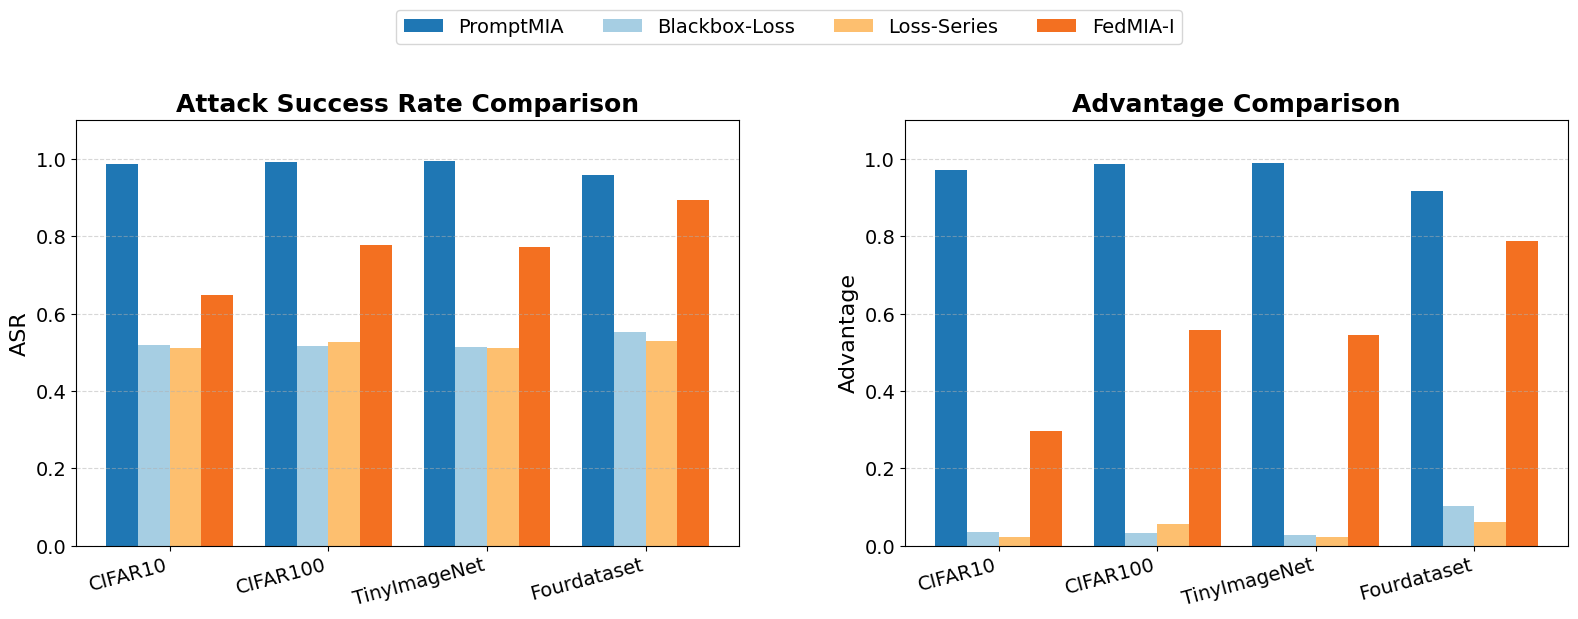

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Globally increase default font size
plt.rcParams.update({'font.size': 14})

# Data derived from the image
datasets = ['CIFAR10', 'CIFAR100', 'TinyImageNet', 'Fourdataset']
models = ['PromptMIA', 'Blackbox-Loss', 'Loss-Series', 'FedMIA-I']

# Estimated colors based on image
colors = ['#1f77b4', '#a6cee3', '#fdbf6f', '#f37021']

# ASR (Attack Success Rate) data
asr_data = {
    'PromptMIA': [0.986, 0.993, 0.995, 0.959],
    'Blackbox-Loss': [0.518, 0.516, 0.515, 0.552],
    'Loss-Series': [0.511, 0.528, 0.511, 0.530],
    'FedMIA-I': [0.649, 0.778, 0.772, 0.895]
}

# Advantage data
adv_data = {
    'PromptMIA': [0.972, 0.986, 0.989, 0.918],
    'Blackbox-Loss': [0.036, 0.032, 0.029, 0.103],
    'Loss-Series': [0.022, 0.057, 0.022, 0.061],
    'FedMIA-I': [0.298, 0.557, 0.544, 0.789]
}

# Set up the figure and subplots
x = np.arange(len(datasets))  # Label locations
width = 0.2  # Width of the bars

# Adjust figure size for width
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Function to draw a grouped bar chart
def plot_bar_chart(ax, data_dict, title, ylabel):
    # Position bars for each group
    offsets = [-1.5 * width, -0.5 * width, 0.5 * width, 1.5 * width]
    
    for i, model in enumerate(models):
        ax.bar(x + offsets[i], data_dict[model], width, label=model, color=colors[i])
        # Note: The ax.bar_label line has been removed to hide the numbers on top

    # Chart formatting with increased font sizes
    ax.set_ylabel(ylabel, fontsize=16)
    ax.set_title(title, fontweight='bold', fontsize=18)
    ax.set_xticks(x)
    
    # Rotate dataset labels slightly and increase tick font sizes
    ax.set_xticklabels(datasets, rotation=15, ha='right', fontsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_ylim(0, 1.1)
    
    # Dashed horizontal grid lines
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Plot ASR Comparison
plot_bar_chart(ax1, asr_data, 'Attack Success Rate Comparison', 'ASR')

# Plot Advantage Comparison
plot_bar_chart(ax2, adv_data, 'Advantage Comparison', 'Advantage')

# Create and position a common legend above the charts with a larger font
legend_elements = [Patch(facecolor=colors[i], label=models[i]) for i in range(len(models))]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(models), frameon=True, fontsize=14)

# Adjust overall layout to fit legend and spacing
plt.tight_layout(rect=[0, 0, 1, 0.93]) 
plt.subplots_adjust(wspace=0.25) 

# Display the charts
plt.show()

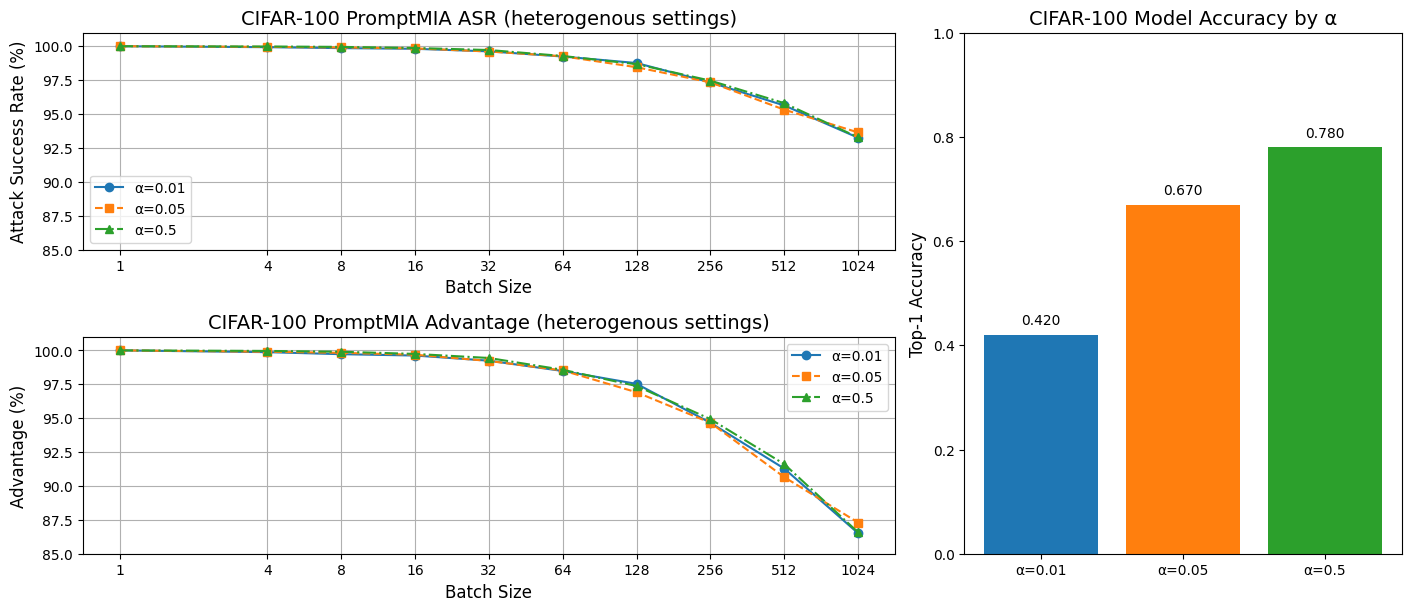

In [21]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

batch_sizes = [1, 4, 8, 16, 32, 64, 128, 256, 512, 1024]

cifar100_a001 = [100.00, 99.93, 99.86, 99.81, 99.62, 99.24, 98.76, 97.33, 95.63,93.25]
cifar100_a005 = [100.00, 99.95, 99.91, 99.84, 99.61, 99.26, 98.45, 97.33, 95.32,93.64]
cifar100_a05  = [100.00, 99.98, 99.95, 99.87, 99.72, 99.28, 98.68, 97.46, 95.80,93.28]

cifar100_adv_a001 = [100.00, 99.87, 99.72, 99.62, 99.24, 98.48, 97.53, 94.66, 91.28,86.51]
cifar100_adv_a005 = [100.00, 99.90, 99.82, 99.68, 99.22, 98.52, 96.91, 94.66, 90.65,87.30]
cifar100_adv_a05  = [100.00, 99.96, 99.90, 99.74, 99.44, 98.57, 97.37, 94.93, 91.61,86.58]

fig = plt.figure(constrained_layout=True, figsize=(14, 6))
gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.3, 0.7])

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(batch_sizes, cifar100_a001, marker='o', linestyle='-', label='α=0.01')
ax1.plot(batch_sizes, cifar100_a005, marker='s', linestyle='--', label='α=0.05')
ax1.plot(batch_sizes, cifar100_a05,  marker='^', linestyle='-.', label='α=0.5')
ax1.set_xscale('log', base=2)
ax1.set_xticks(batch_sizes)
ax1.set_xticklabels(batch_sizes)
ax1.set_ylim(85, 101)
ax1.set_title('CIFAR-100 PromptMIA ASR (heterogenous settings)', fontsize=14)
ax1.set_xlabel('Batch Size', fontsize=12)
ax1.set_ylabel('Attack Success Rate (%)', fontsize=12)
ax1.grid(True)
ax1.legend(fontsize=10)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(batch_sizes, cifar100_adv_a001, marker='o', linestyle='-', label='α=0.01')
ax3.plot(batch_sizes, cifar100_adv_a005, marker='s', linestyle='--', label='α=0.05')
ax3.plot(batch_sizes, cifar100_adv_a05,  marker='^', linestyle='-.', label='α=0.5')
ax3.set_xscale('log', base=2)
ax3.set_xticks(batch_sizes)
ax3.set_xticklabels(batch_sizes)
ax3.set_ylim(85, 101)
ax3.set_title('CIFAR-100 PromptMIA Advantage (heterogenous settings)', fontsize=14)
ax3.set_xlabel('Batch Size', fontsize=12)
ax3.set_ylabel('Advantage (%)', fontsize=12)
ax3.grid(True)
ax3.legend(fontsize=10)

ax2 = fig.add_subplot(gs[:, 1])
acc_labels = ['α=0.01', 'α=0.05', 'α=0.5']
model_acc = [0.42, 0.67, 0.78]
ax2.bar(acc_labels, model_acc, color=['tab:blue','tab:orange','tab:green'])
ax2.set_ylim(0, 1.0)
ax2.set_title('CIFAR-100 Model Accuracy by α', fontsize=14)
ax2.set_ylabel('Top-1 Accuracy', fontsize=12)
for i, v in enumerate(model_acc):
    ax2.text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=10)

plt.show()

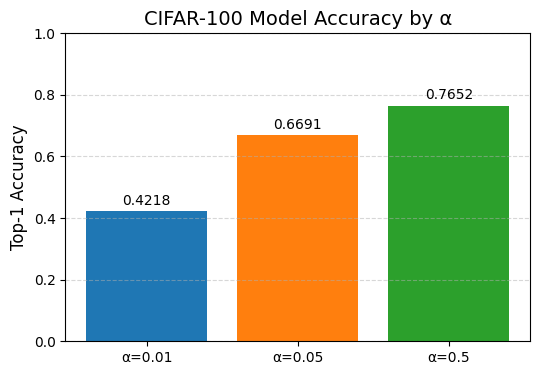

In [22]:
import matplotlib.pyplot as plt

acc_labels = ['α=0.01', 'α=0.05', 'α=0.5']
model_acc = [0.4218, 0.6691, 0.7652]

plt.figure(figsize=(6, 4))
plt.bar(acc_labels, model_acc, color=['tab:blue', 'tab:orange', 'tab:green'])
plt.ylim(0, 1.0)
plt.title('CIFAR-100 Model Accuracy by α', fontsize=14)
plt.ylabel('Top-1 Accuracy', fontsize=12)
for i, v in enumerate(model_acc):
    plt.text(i, v + 0.02, f'{v:.4f}', ha='center', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [32]:
import numpy as np, torch, torchvision, os
import torch.utils.data as Data
from data_util.DataTransformBuilder import build_data_transform
from Models.L2P_heuristic_model import L2P_ViT_B32
from util.TOdevice import to_device
from util.saving_tools import load_model_trainable_part

def l2_normalize(x, dim=1, eps=1e-12):
    return x / (x.norm(dim=dim, keepdim=True) + eps)

def estimate_sigmas(feats_norm, keys_norm):
    K, D = keys_norm.shape
    sims = feats_norm @ keys_norm.T
    assignments = np.argmax(sims, axis=1)
    sigmas = np.zeros(K)
    counts = np.zeros(K, dtype=int)
    for i in range(K):
        members = feats_norm[assignments == i]
        counts[i] = len(members)
        if len(members) < 2:
            sigmas[i] = np.nan
        else:
            diffs = members - keys_norm[i]
            sq_dists = np.sum(diffs**2, axis=1)
            sigmas[i] = np.sqrt(np.mean(sq_dists) / D)
    return sigmas, counts

norm_stats = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
tp = build_data_transform(norm_stats, 256, 224, train_augment=False)
trainset = torchvision.datasets.CIFAR10(root='./Dataset', train=True, download=False, transform=tp)

model = L2P_ViT_B32(prompt_method='shallow', batchwise_prompt=False, pool_size=20, top_k=4, num_classes=10, candidate_key=None)
model = to_device(model, 'cuda')
model.build_trainable_keys()
load_model_trainable_part(model, 'output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt')

# Extract all training features once
loader = Data.DataLoader(trainset, batch_size=128, shuffle=False, num_workers=4)
all_feats = []
with torch.no_grad():
    for x, _ in loader:
        x = to_device(x, 'cuda').float()
        all_feats.append(model.get_cls_keys(x).cpu())
all_feats = torch.cat(all_feats, dim=0)
all_feats_norm = l2_normalize(all_feats).numpy()
print(f"Total features extracted: {all_feats_norm.shape[0]}")

keys = model.pool.key.detach().cpu()
keys_norm = l2_normalize(keys).numpy()
M = 20

# Test different sample sizes
sample_sizes = [50, 100, 200, 500, 1000]
n_trials = 10  # repeat each to get error statistics

print(f"\n{'n_samples':>10s} | {'mean_abs_err':>13s} | {'max_abs_err':>13s} | {'mean_rel_err%':>14s} | {'max_rel_err%':>13s} | {'min_cluster_n':>14s}")
print("-" * 95)

N_total = all_feats_norm.shape[0]
for n in sample_sizes:
    abs_errs = []
    rel_errs = []
    min_cluster_ns = []

    for trial in range(n_trials):
        n_use = min(n, N_total - 1)
        idx = np.random.choice(N_total, n_use, replace=False)
        mask = np.ones(N_total, dtype=bool)
        mask[idx] = False

        # Estimate sigma on selected public samples
        est_subset = all_feats_norm[idx]
        est_sigmas, est_counts = estimate_sigmas(est_subset, keys_norm)

        # Ground truth sigma on the remaining data (disjoint from estimate set)
        gt_subset = all_feats_norm[mask]
        gt_sigmas, _ = estimate_sigmas(gt_subset, keys_norm)

        # Compare only clusters that are well-defined in both estimates
        valid = (~np.isnan(est_sigmas)) & (~np.isnan(gt_sigmas))
        if valid.sum() == 0:
            continue

        ae = np.abs(est_sigmas[valid] - gt_sigmas[valid])
        re = ae / gt_sigmas[valid] * 100
        abs_errs.append(ae)
        rel_errs.append(re)
        min_cluster_ns.append(est_counts[valid].min())

    if abs_errs:
        all_ae = np.concatenate(abs_errs)
        all_re = np.concatenate(rel_errs)
        mcn = min(min_cluster_ns)
        print(f"{n:>10d} | {np.mean(all_ae):>13.6f} | {np.max(all_ae):>13.6f} | {np.mean(all_re):>13.2f}% | {np.max(all_re):>12.2f}% | {mcn:>14d}")

/home/quannm/.local/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Total features extracted: 50000

 n_samples |  mean_abs_err |   max_abs_err |  mean_rel_err% |  max_rel_err% |  min_cluster_n
-----------------------------------------------------------------------------------------------
        50 |      0.001433 |      0.005075 |          4.22% |        14.34% |              2
       100 |      0.001188 |      0.005458 |          3.43% |        15.20% |              2
       200 |      0.000881 |      0.005004 |          2.51% |        13.64% |              2
       500 |      0.000748 |      0.004985 |          2.14% |        16.64% |              2
      1000 |      0.000725 |      0.008074 |          2.08% |        21.87% |              2


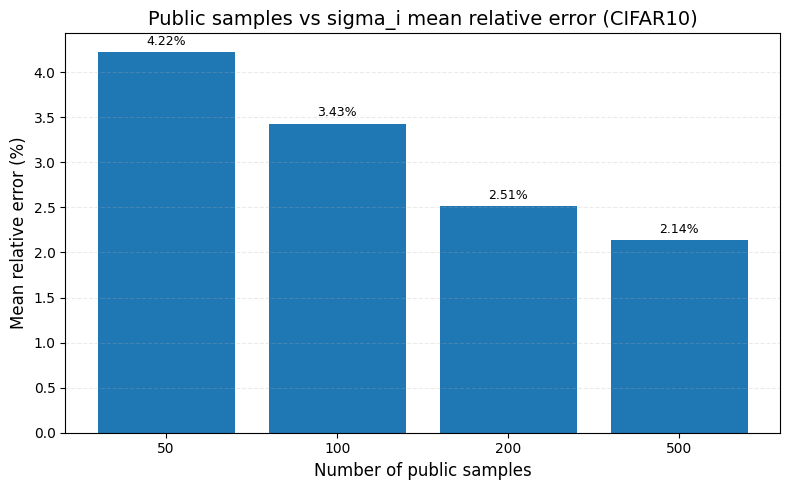

In [34]:
import matplotlib.pyplot as plt

n_samples = [50, 100, 200, 500]
mean_rel_err = [4.22, 3.43,  2.51, 2.14]

# Use categorical labels so bars are evenly spaced like a regular bar chart
x_labels = [str(n) for n in n_samples]

plt.figure(figsize=(8, 5))
bars = plt.bar(x_labels, mean_rel_err, color='tab:blue')
plt.xlabel('Number of public samples', fontsize=12)
plt.ylabel('Mean relative error (%)', fontsize=12)
plt.title('Public samples vs sigma_i mean relative error (CIFAR10)', fontsize=14)
for bar, v in zip(bars, mean_rel_err):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.08, f'{v:.2f}%', ha='center', fontsize=9)
plt.grid(True, axis='y', linestyle='--', alpha=0.25)
plt.tight_layout()
plt.show()

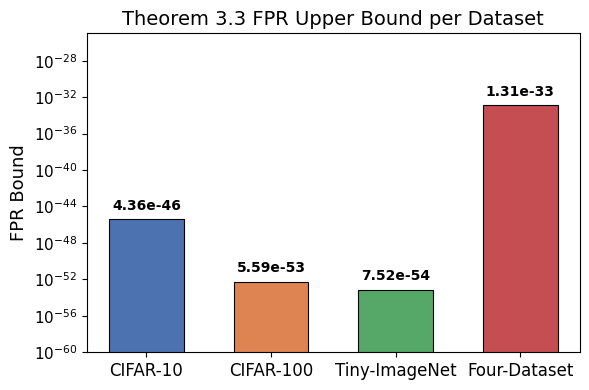

In [3]:
import matplotlib.pyplot as plt
import numpy as np

datasets = ['CIFAR-10', 'CIFAR-100', 'Tiny-ImageNet', 'Four-Dataset']
fpr_bounds = [4.361278e-46, 5.585532e-53, 7.515520e-54, 1.306107e-33]

fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
bars = ax.bar(datasets, fpr_bounds, color=colors, width=0.6, edgecolor='black', linewidth=0.8)

ax.set_yscale('log')
ax.set_ylabel('FPR Bound', fontsize=13)
ax.set_title('Theorem 3.3 FPR Upper Bound per Dataset', fontsize=14)

for bar, val in zip(bars, fpr_bounds):
    ax.text(bar.get_x() + bar.get_width() / 2, val * 5,
            f'{val:.2e}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(1e-60, 1e-25)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=11)
plt.tight_layout()
plt.savefig('fpr_bound_bar.pdf', bbox_inches='tight')
plt.show()

In [ ]:
#CIFAR100 alpha = 0.5 bound is  5.585532e-53, 0.05 bound is 3.458339e-47
# CIFAR100 alpha 0.5 model acc is 0.78. 0.05 model acc is 0.66

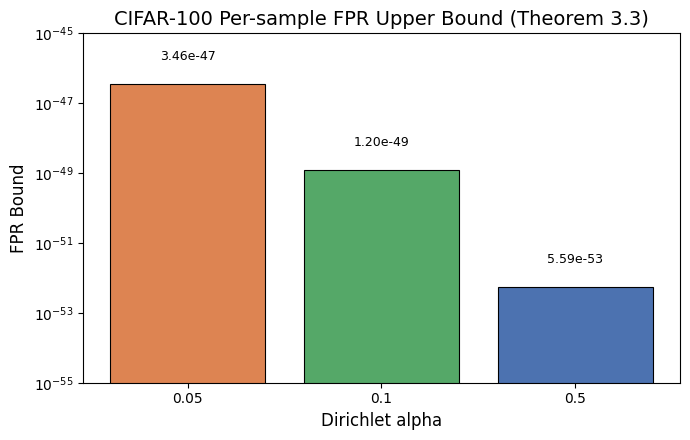

In [7]:
import matplotlib.pyplot as plt

alphas = ['0.05', '0.1', '0.5']
fpr_bounds = [3.458339e-47, 1.197672e-49, 5.585532e-53]
colors = ['#DD8452', '#55A868', '#4C72B0']

plt.figure(figsize=(7, 4.5))
bars = plt.bar(alphas, fpr_bounds, color=colors, edgecolor='black', linewidth=0.8)
plt.yscale('log')
plt.title('CIFAR-100 Per-sample FPR Upper Bound (Theorem 3.3)', fontsize=14)
plt.xlabel('Dirichlet alpha', fontsize=12)
plt.ylabel('FPR Bound', fontsize=12)

for bar, value in zip(bars, fpr_bounds):
    plt.text(bar.get_x() + bar.get_width() / 2, value * 4, f'{value:.2e}', ha='center', va='bottom', fontsize=9)

plt.ylim(1e-55, 1e-45)
plt.tight_layout()
plt.show()

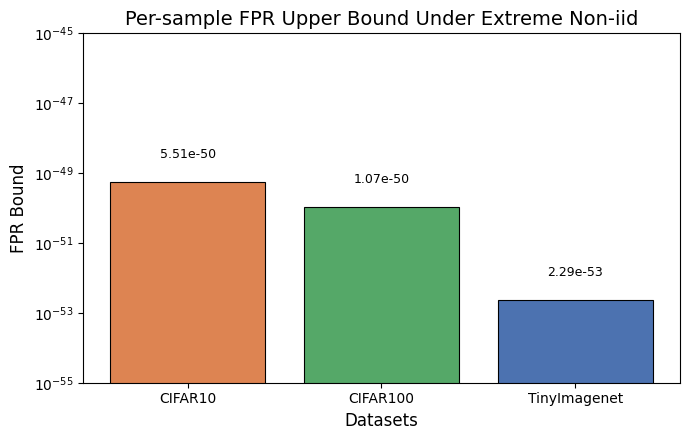

In [2]:
import matplotlib.pyplot as plt

alphas = ['CIFAR10', 'CIFAR100', 'TinyImagenet']
fpr_bounds = [5.512331e-50, 1.071513e-50, 2.291793e-53]
colors = ['#DD8452', '#55A868', '#4C72B0']

plt.figure(figsize=(7, 4.5))
bars = plt.bar(alphas, fpr_bounds, color=colors, edgecolor='black', linewidth=0.8)
plt.yscale('log')
plt.title('Per-sample FPR Upper Bound Under Extreme Non-iid', fontsize=14)
plt.xlabel('Datasets', fontsize=12)
plt.ylabel('FPR Bound', fontsize=12)

for bar, value in zip(bars, fpr_bounds):
    plt.text(bar.get_x() + bar.get_width() / 2, value * 4, f'{value:.2e}', ha='center', va='bottom', fontsize=9)

plt.ylim(1e-55, 1e-45)
plt.tight_layout()
plt.show()